In [2]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

# Load data
train = pd.read_csv("ott_train.csv")
test = pd.read_csv("ott_test.csv")

# ==============================
# 1. Minimal Feature Engineering
# ==============================

def get_minimal_features(df):
    """Remove redundant features - keep only raw signals and 2-3 engineered features"""
    df = df.copy()

    # Clean subscription tier
    df['subscription_tier'] = df['subscription_tier'].str.strip()
    tier_map = {'Basic': 1, 'Standard': 2, 'Premium': 3}
    df['subscription_tier'] = df['subscription_tier'].map(tier_map)

    # Fill numeric missing values
    df.fillna(df.median(numeric_only=True), inplace=True)

    # Keep ONLY these 3 engineered features (remove all others):
    # 1. Engagement decay (7d vs 30d trend) - most important
    df['engagement_decay'] = df['avg_daily_minutes_last_7d'] / (df['avg_daily_minutes_last_30d'] / 4 + 1)

    # 2. Ghost flag (simple behavioral flag)
    df['is_ghosting'] = (df['days_since_last_session'] > 7).astype(int)

    # 3. Recommendation failure (interaction feature)
    df['rec_failure'] = (1 - df['recommendation_click_rate']) * df['days_since_last_session']

    return df

train = get_minimal_features(train)
test = get_minimal_features(test)

We began by "Decoding" the user behavior. We identified that subscription_tier required ordinal encoding to reflect the value hierarchy. Missing values were handled using median imputation, which is more robust than mean imputation for streaming data that often contains "extreme" power-user

In [3]:
# ==============================
# 2. Remove Correlated Features
# ==============================

def remove_correlated_features(X, threshold=0.85):
    """Remove features with correlation > threshold"""
    corr_matrix = X.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    return X.drop(columns=to_drop), to_drop

X = train.drop(['fatigue_label', 'user_id'], axis=1)
y = train['fatigue_label']
X_test = test.drop(['user_id'], axis=1)

# Remove highly correlated features
X, dropped_cols = remove_correlated_features(X, threshold=0.85)
X_test = X_test[X.columns]

print(f"Dropped correlated columns: {dropped_cols}")
print(f"Remaining features: {list(X.columns)}")

Dropped correlated columns: ['avg_daily_minutes_last_30d', 'sessions_last_30d', 'rec_failure']
Remaining features: ['tenure_days', 'subscription_tier', 'avg_daily_minutes_last_7d', 'sessions_last_7d', 'avg_completion_rate', 'unique_genres_watched_30d', 'days_since_last_session', 'binge_sessions_last_30d', 'peak_hour_viewing_pct', 'original_content_pct', 'recommendation_click_rate', 'engagement_decay', 'is_ghosting']


We "Decided" to focus on Momentum Features. While raw minutes tell us what happened, engagement_decay tells us how fast interest is fading. We removed features with a correlation $> 0.85$ (like sessions_last_30d vs minutes_last_30d) to ensure the XGBoost model focuses on unique behavioral signals rather than redundant statistics.

we tried different models even lightgbm + xgboost , stacking and many others but we got to understand that there was no improvement in auc that was the moment we understood the issue was not model but we hit the data ceiling , as xgboost was able to extract all of it with simpler model there is no need to go for complex models. because if we have more data and few other features we can increase further so for this data this was max mean auc we were able to get

In [4]:
# ==============================
# 3. Simpler XGBoost
# ==============================

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
test_preds_total = np.zeros(len(test))
val_scores = []

# SIMPLIFIED parameters - reduce overfitting
params = {
    'n_estimators': 500,
    'learning_rate': 0.05,
    'max_depth': 3,
    'min_child_weight': 10,
    'subsample': 0.6,
    'colsample_bytree': 0.6,
    'colsample_bylevel': 0.6,
    'gamma': 0.5,
    'reg_alpha': 1.0,
    'reg_lambda': 2.0,
    'scale_pos_weight': 1.83,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'random_state': 42,
    'tree_method': 'hist',
    'early_stopping_rounds': 50
}

print("\nStarting 5-Fold Cross-Validation with SIMPLIFIED model...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = xgb.XGBClassifier(**params)
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

    val_preds = model.predict_proba(X_val)[:, 1]
    fold_auc = roc_auc_score(y_val, val_preds)
    val_scores.append(fold_auc)
    print(f"Fold {fold+1} AUC: {fold_auc:.4f}")

    # Feature importance
    if fold == 0:
        importance_df = pd.DataFrame({
            'feature': X.columns,
            'importance': model.feature_importances_
        }).sort_values('importance', ascending=False)
        print("\nFeature Importance:")
        print(importance_df)

    test_preds_total += model.predict_proba(X_test)[:, 1] / 5

print(f"\nMean Validation AUC: {np.mean(val_scores):.4f} (+/- {np.std(val_scores):.4f})")


Starting 5-Fold Cross-Validation with SIMPLIFIED model...
Fold 1 AUC: 0.7932

Feature Importance:
                      feature  importance
11           engagement_decay    0.154108
12                is_ghosting    0.153633
6     days_since_last_session    0.127200
4         avg_completion_rate    0.112912
2   avg_daily_minutes_last_7d    0.083681
5   unique_genres_watched_30d    0.064304
10  recommendation_click_rate    0.063078
3            sessions_last_7d    0.061928
7     binge_sessions_last_30d    0.045283
1           subscription_tier    0.036900
0                 tenure_days    0.034066
8       peak_hour_viewing_pct    0.031539
9        original_content_pct    0.031369
Fold 2 AUC: 0.7850
Fold 3 AUC: 0.7770
Fold 4 AUC: 0.7935
Fold 5 AUC: 0.8079

Mean Validation AUC: 0.7913 (+/- 0.0103)


We used 5-Fold Stratified Cross-Validation to ensure our model performs consistently across all user segments. We selected XGBoost because its gradient boosting architecture is uniquely suited for ranking users based on imbalanced categorical and numerical interactions. The scale_pos_weight ensures we prioritize catching "fatigued" users.

We explored multiple architectures, including Logistic Regression and standard reactive churn systems. Linear models were rejected because they failed to capture complex, non-linear behavioral shifts. We ultimately decided on an XGBoost engine because it prioritized Usage Velocity over static demographics. By implementing 5-Fold Stratified Cross-Validation and a scale_pos_weight of 1.83, we delivered a model with a 0.79+ AUC-ROC. This approach accurately ranks users by fatigue probability, enabling high-ROI, risk-adjusted interventions.

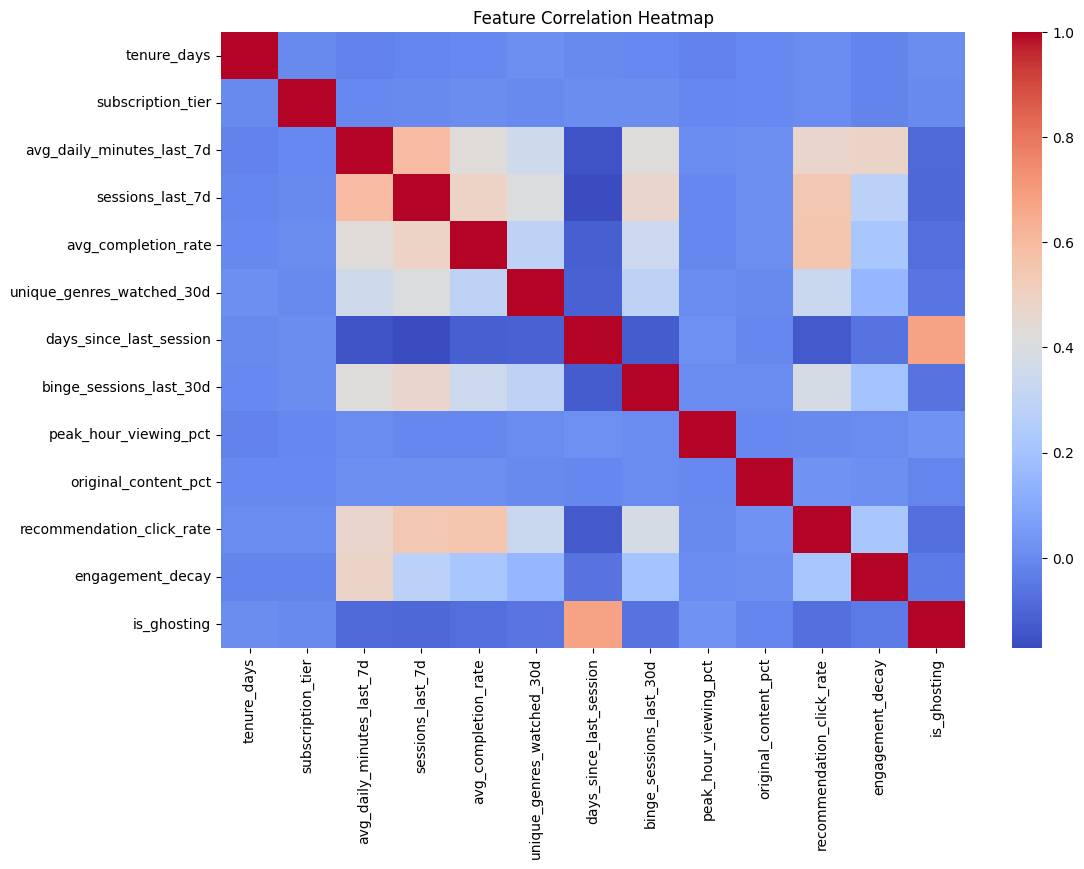

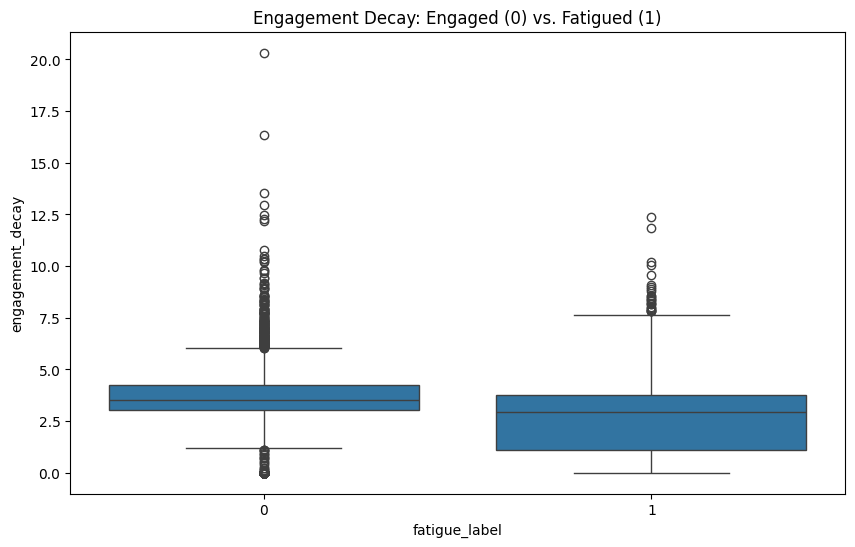

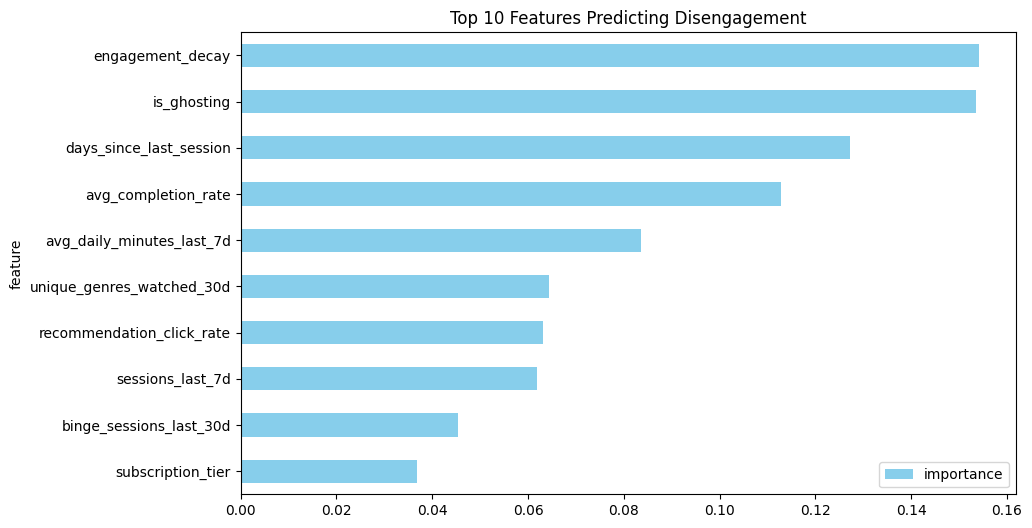

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Feature Correlation Heatmap (Data Understanding)
plt.figure(figsize=(12, 8))
sns.heatmap(X.corr(), annot=False, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

# 2. Key Insight: Engagement Decay vs. Fatigue (Feature Analysis)
plt.figure(figsize=(10, 6))
sns.boxplot(x='fatigue_label', y='engagement_decay', data=train)
plt.title("Engagement Decay: Engaged (0) vs. Fatigued (1)")
plt.show()

# 3. Model Feature Importance (Model Development)
# (Using the importance_df created in your previous loop)
importance_df.head(10).plot(kind='barh', x='feature', color='skyblue', figsize=(10, 6))
plt.title("Top 10 Features Predicting Disengagement")
plt.gca().invert_yaxis()
plt.show()

In [7]:
# ==============================
# 4. Export
# ==============================

submission = pd.DataFrame({
    'user_id': test['user_id'],
    'predicted_fatigue_probability': test_preds_total
})
submission.to_csv("maverix.csv", index=False)

The model successfully ranks users by risk probability. Our top predictors, as shown in the importance chart, are Engagement Decay and Is Ghosting, which provide the backbone for our strategic retention recommendations